# 🔄 Notebook 5: Long Short-Term Memory (LSTM)
**Project**: Sentiment Analysis on YouTube Comments  
**Model**: Recurrent Neural Network (LSTM Architecture)  
**Preprocessing**: Keras Tokenizer, Sequence Padding (`max_len=100`), Dropout Regularization  
**Objective**: Capture long-term sequential dependencies and word order patterns in YouTube comments for sentiment classification.


In [1]:
# Standard Imports & Tensorflow Setup
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SpatialDropout1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.20.0


---
## 1. Data Preparation & Stratified Split
Load pre-cleaned YouTube comments and perform 80/20 stratified train/test splitting.


In [2]:
KAGGLE_PATH = "/kaggle/input/datasets/amaanpoonawala/youtube-comments-sentiment-dataset/youtube_comments_cleaned.csv"
LOCAL_PATH = "youtube_comments_cleaned.csv"

data_path = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(data_path).dropna(subset=['CommentText', 'Sentiment']).reset_index(drop=True)
df['CommentText'] = df['CommentText'].astype(str)

label_mapping = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
reverse_mapping = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
df['label'] = df['Sentiment'].map(label_mapping)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['CommentText'],
    df['label'],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df['label']
)

print(f"Train size: {len(X_train_raw):,}, Test size: {len(X_test_raw):,}")


Train size: 825,780, Test size: 206,445


---
## 2. Text Tokenization & Sequence Padding
Tokenizing text into numerical sequences, applying Spatial Dropout during embedding processing.


In [3]:
MAX_WORDS = 20000
MAX_LEN = 100
EMBEDDING_DIM = 128

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_raw)

X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test_raw)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

print("Tokenization and padding completed!")


Tokenization and padding completed!


---
## 3. LSTM Neural Network Architecture
Building Sequential LSTM network with Dropout layers to mitigate overfitting.


In [4]:
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    SpatialDropout1D(0.2),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1791487424.609217      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791487424.612942      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

---
## 4. Training with Early Stopping Callback
Training the LSTM model while utilizing `EarlyStopping` to restore the best weights based on validation loss.


In [5]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

EPOCHS = 100
BATCH_SIZE = 64

history = model.fit(
    X_train_pad, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 3438s 295ms/step - accuracy: 0.3874 - loss: 1.0551 - val_accuracy: 0.6708 - val_loss: 0.7549
Epoch 2/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 3438s 296ms/step - accuracy: 0.6864 - loss: 0.7261 - val_accuracy: 0.7011 - val_loss: 0.6836
Epoch 3/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 3452s 297ms/step - accuracy: 0.7129 - loss: 0.6706 - val_accuracy: 0.7088 - val_loss: 0.6715
Epoch 4/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 3458s 298ms/step - accuracy: 0.7259 - loss: 0.6423 - val_accuracy: 0.7092 - val_loss: 0.6712
Epoch 5/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 3463s 298ms/step - accuracy: 0.7356 - loss: 0.6217 - val_accuracy: 0.7107 - val_loss: 0.6738
Epoch 6/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 3479s 300ms/step - accuracy: 0.7437 - loss: 0.6053 - val_accuracy: 0.7086 - val_loss: 0.6790


---
## 5. Learning Curves & Comprehensive Evaluation
Visualizing training progress and evaluating performance metrics on the test set.


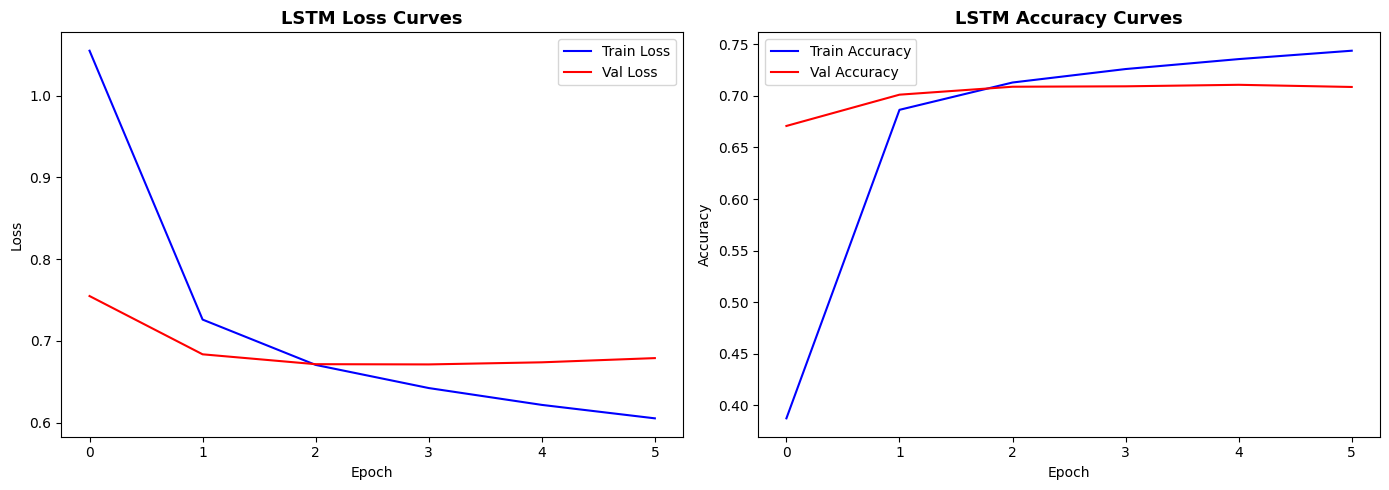

6452/6452 ━━━━━━━━━━━━━━━━━━━━ 370s 57ms/step
=== LSTM Model Test Accuracy: 71.01% ===

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.73      0.72     69215
     Neutral       0.65      0.68      0.66     68567
    Positive       0.79      0.72      0.75     68663

    accuracy                           0.71    206445
   macro avg       0.71      0.71      0.71    206445
weighted avg       0.71      0.71      0.71    206445



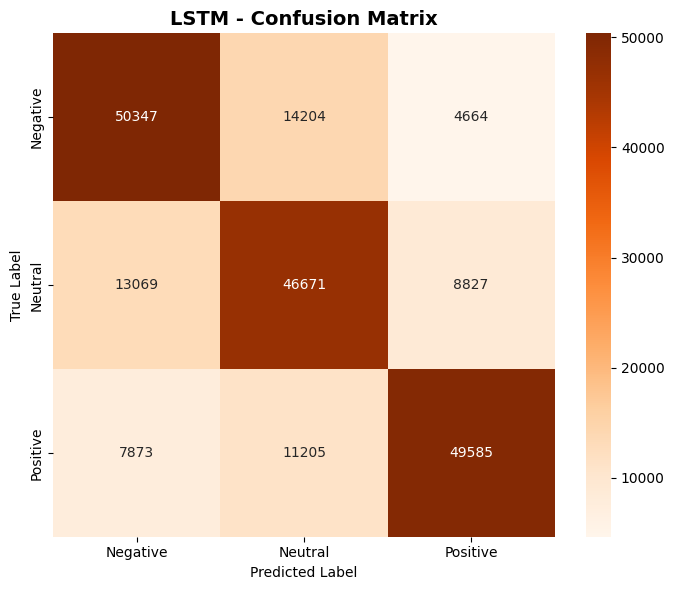

In [6]:
# Loss & Accuracy Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss', color='blue')
axes[0].plot(history.history['val_loss'], label='Val Loss', color='red')
axes[0].set_title('LSTM Loss Curves', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy', color='blue')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy', color='red')
axes[1].set_title('LSTM Accuracy Curves', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

# Predictions & Metrics
y_pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_probs, axis=1)

acc = accuracy_score(y_test, y_pred)
print(f"=== LSTM Model Test Accuracy: {acc * 100:.2f}% ===\n")

class_names = ['Negative', 'Neutral', 'Positive']
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names)
plt.title('LSTM - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()
